<a href="https://colab.research.google.com/github/jatinkumar-creator/machine-learning-portfolio/blob/main/07_Recommendation_Systems/notebooks/03_Movie_Recommendation_System_Real_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 31: Movie Recommendation System Using MovieLens

## Objective
Build a collaborative filtering movie recommendation system
using real-world user ratings.

## Dataset
MovieLens Latest Small by GroupLens.

## Techniques
- Exploratory Data Analysis
- User-Item Interaction Matrix
- User-Based Collaborative Filtering
- Cosine Similarity
- Top-N Recommendations
- Rating Prediction
- MAE and RMSE Evaluation

## Tools
Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn

In [1]:
#Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import mean_absolute_error, mean_squared_error

import zipfile
import urllib.request
import os

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
#Download the dataset
url = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"

urllib.request.urlretrieve(url, "movielens.zip")

with zipfile.ZipFile("movielens.zip", "r") as zip_ref:
    zip_ref.extractall(".")

print("Dataset downloaded and extracted.")

Dataset downloaded and extracted.


In [3]:
#Load the CSV files
ratings = pd.read_csv("ml-latest-small/ratings.csv")
movies = pd.read_csv("ml-latest-small/movies.csv")

print("Ratings dataset:")
display(ratings.head())

print("Movies dataset:")
display(movies.head())

Ratings dataset:


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


Movies dataset:


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


The ratings file contains:
    **Column**	               **Meaning**
      userId	            Unique user identifier
      movieId	            Unique movie identifier
      rating	            User's movie rating
     timestamp	  Time when the rating was recorded

The movies file contains:
      **Column**	              **Meaning**
        movieId	            Movie identifier
        title	         Movie title and release year
        genres	           Movie genres

The movieId column connects the two datasets.

In [4]:
#Explore the dataset
print("Ratings shape:", ratings.shape)
print("Movies shape:", movies.shape)

print("\nNumber of unique users:", ratings["userId"].nunique())
print("Number of unique movies rated:", ratings["movieId"].nunique())

print("\nMissing values:")
print(ratings.isnull().sum())

print("\nDuplicate rows:", ratings.duplicated().sum())

print("\nRating statistics:")
print(ratings["rating"].describe())

Ratings shape: (100836, 4)
Movies shape: (9742, 3)

Number of unique users: 610
Number of unique movies rated: 9724

Missing values:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Duplicate rows: 0

Rating statistics:
count    100836.000000
mean          3.501557
std           1.042529
min           0.500000
25%           3.000000
50%           3.500000
75%           4.000000
max           5.000000
Name: rating, dtype: float64


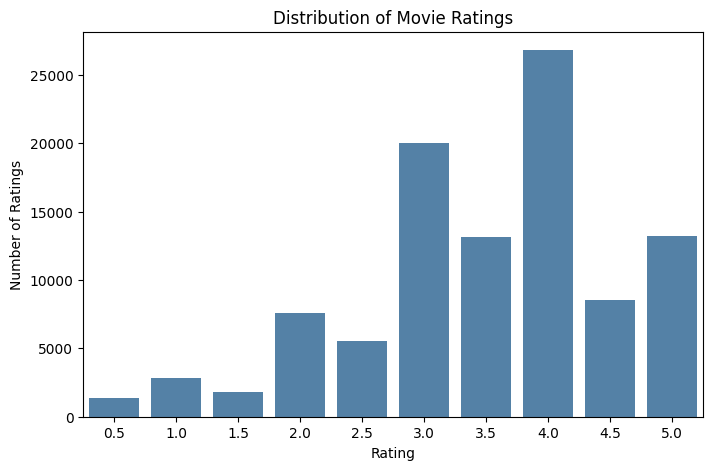

In [5]:
#Visualize rating distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=ratings,
    x="rating",
    color="steelblue"
)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.show()

In [6]:
#Find the most-rated movies
movie_rating_counts = (
    ratings.groupby("movieId")
    .size()
    .reset_index(name="rating_count")
)

popular_movies = movie_rating_counts.merge(
    movies,
    on="movieId"
)

popular_movies = popular_movies.sort_values(
    by="rating_count",
    ascending=False
)

display(
    popular_movies[
        ["title", "rating_count", "genres"]
    ].head(10)
)

,title,rating_count,genres
314,Forrest Gump (1994),329,Comedy|Drama|Romance|War
277,"Shawshank Redemption, The (1994)",317,Crime|Drama
257,Pulp Fiction (1994),307,Comedy|Crime|Drama|Thriller
510,"Silence of the Lambs, The (1991)",279,Crime|Horror|Thriller
1938,"Matrix, The (1999)",278,Action|Sci-Fi|Thriller
224,Star Wars: Episode IV - A New Hope (1977),251,Action|Adventure|Sci-Fi
418,Jurassic Park (1993),238,Action|Adventure|Sci-Fi|Thriller
97,Braveheart (1995),237,Action|Drama|War
507,Terminator 2: Judgment Day (1991),224,Action|Sci-Fi
461,Schindler's List (1993),220,Drama|War


In [7]:
#Train-test split
train_ratings, test_ratings = train_test_split(
    ratings,
    test_size=0.20,
    random_state=42
)

print("Training ratings:", train_ratings.shape)
print("Testing ratings:", test_ratings.shape)

Training ratings: (80668, 4)
Testing ratings: (20168, 4)


In [8]:
#Create the training matrix
user_movie_matrix = train_ratings.pivot_table(
    index="userId",
    columns="movieId",
    values="rating"
)

user_movie_matrix_filled = user_movie_matrix.fillna(0)

print("User-movie matrix shape:", user_movie_matrix.shape)

display(user_movie_matrix.head())

User-movie matrix shape: (610, 8983)


movieId,1,2,3,4,5,6,7,8,9,10,...,191005,193565,193571,193573,193579,193581,193583,193585,193587,193609
userId,,,,,,,,,,,,,,,,,,,,,
1,4.0,NaN,4.0,NaN,NaN,4.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
#Calculate user similarity
user_similarity = cosine_similarity(
    user_movie_matrix_filled
)

user_similarity_df = pd.DataFrame(
    user_similarity,
    index=user_movie_matrix.index,
    columns=user_movie_matrix.index
)

display(user_similarity_df.iloc[:5, :5])

userId,1,2,3,4,5
userId,,,,,
1,1.000000,0.016314,0.049021,0.165799,0.123392
2,0.016314,1.000000,0.000000,0.004627,0.000000
3,0.049021,0.000000,1.000000,0.000000,0.005770
4,0.165799,0.004627,0.000000,1.000000,0.133565
5,0.123392,0.000000,0.005770,0.133565,1.000000


In [10]:
#Create the rating prediction function
def predict_rating(user_id, movie_id, k=20):

    # Check whether the user and movie exist in training data
    if user_id not in user_similarity_df.index:
        return train_ratings["rating"].mean()

    if movie_id not in user_movie_matrix.columns:
        return train_ratings["rating"].mean()

    # Get similarity scores for the target user
    similarities = user_similarity_df[user_id]

    # Get ratings given to this movie by other users
    movie_ratings = user_movie_matrix[movie_id].dropna()

    # Exclude the target user
    movie_ratings = movie_ratings.drop(
        index=user_id,
        errors="ignore"
    )

    # Keep users who have rated this movie
    common_users = movie_ratings.index.intersection(
        similarities.index
    )

    movie_ratings = movie_ratings.loc[common_users]
    similarities = similarities.loc[common_users]

    # Keep only positive similarities
    positive_similarity = similarities[similarities > 0]

    # Select the k most similar users
    top_users = positive_similarity.nlargest(k)

    # If no similar users are available, use the training mean
    if len(top_users) == 0:
        return train_ratings["rating"].mean()

    # Get ratings of selected neighbors
    neighbor_ratings = movie_ratings.loc[top_users.index]

    # Calculate similarity-weighted rating
    prediction = np.dot(
        top_users.values,
        neighbor_ratings.values
    ) / top_users.values.sum()

    # Ratings in MovieLens range from 0.5 to 5.0
    return np.clip(prediction, 0.5, 5.0)

In [11]:
#Test one prediction
sample = test_ratings.iloc[0]

user_id = sample["userId"]
movie_id = sample["movieId"]
actual_rating = sample["rating"]

predicted_rating = predict_rating(
    user_id,
    movie_id
)

movie_title = movies.loc[
    movies["movieId"] == movie_id,
    "title"
].iloc[0]

print("User ID:", user_id)
print("Movie:", movie_title)
print("Actual rating:", actual_rating)
print("Predicted rating:", round(predicted_rating, 2))

User ID: 432.0
Movie: Robin Hood (2010)
Actual rating: 4.5
Predicted rating: 2.91


In [12]:
#Evaluate on the test set
# Use a manageable sample first so the notebook runs smoothly
evaluation_sample = test_ratings.sample(
    n=min(2000, len(test_ratings)),
    random_state=42
)

actual_ratings = []
predicted_ratings = []

for row in evaluation_sample.itertuples(index=False):

    prediction = predict_rating(
        row.userId,
        row.movieId
    )

    actual_ratings.append(row.rating)
    predicted_ratings.append(prediction)

mae = mean_absolute_error(
    actual_ratings,
    predicted_ratings
)

rmse = np.sqrt(
    mean_squared_error(
        actual_ratings,
        predicted_ratings
    )
)

print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))

MAE: 0.7641
RMSE: 0.9824


In [13]:
#Recommendation function
def recommend_movies(user_id, k=20, n_recommendations=10):

    if user_id not in user_similarity_df.index:
        print("User not found in training data.")
        return pd.DataFrame()

    # Similarity scores for the selected user
    similarities = user_similarity_df[user_id]

    # Exclude the user themselves
    similarities = similarities.drop(
        index=user_id,
        errors="ignore"
    )

    # Select the most similar users
    neighbors = similarities[
        similarities > 0
    ].nlargest(k)

    if len(neighbors) == 0:
        print("No similar users found.")
        return pd.DataFrame()

    # Movies already rated by the target user
    watched_movies = set(
        train_ratings.loc[
            train_ratings["userId"] == user_id,
            "movieId"
        ]
    )

    # Calculate recommendation scores
    scores = {}

    for neighbor_id, similarity in neighbors.items():

        neighbor_ratings = user_movie_matrix.loc[
            neighbor_id
        ].dropna()

        for movie_id, rating in neighbor_ratings.items():

            if movie_id not in watched_movies:

                if movie_id not in scores:
                    scores[movie_id] = [0, 0]

                scores[movie_id][0] += similarity * rating
                scores[movie_id][1] += similarity

    # Convert scores into a ranked list
    recommendations = []

    for movie_id, values in scores.items():

        weighted_score = values[0] / values[1]

        recommendations.append({
            "movieId": movie_id,
            "predicted_rating": weighted_score
        })

    recommendations_df = pd.DataFrame(recommendations)

    if recommendations_df.empty:
        return recommendations_df

    recommendations_df = recommendations_df.merge(
        movies,
        on="movieId"
    )

    recommendations_df = recommendations_df.sort_values(
        by="predicted_rating",
        ascending=False
    )

    return recommendations_df[
        ["title", "genres", "predicted_rating"]
    ].head(n_recommendations)

In [14]:
#Generate recommendations for a user
# Select a user from the training dataset
sample_user_id = train_ratings["userId"].iloc[0]

print("Recommendations for User:", sample_user_id)

recommendations = recommend_movies(
    sample_user_id,
    k=20,
    n_recommendations=10
)

display(recommendations)

Recommendations for User: 509


,title,genres,predicted_rating
337,"Apartment, The (1960)",Comedy|Drama|Romance,5.0
1434,Strictly Sexual (2008),Comedy|Drama|Romance,5.0
2616,Bull Durham (1988),Comedy|Drama|Romance,5.0
1565,Millennium Actress (Sennen joyû) (2001),Animation|Drama|Romance,5.0
1482,"City of Lost Children, The (Cité des enfants p...",Adventure|Drama|Fantasy|Mystery|Sci-Fi,5.0
2508,Nightcrawler (2014),Crime|Drama|Thriller,5.0
2574,Babes in Toyland (1934),Children|Comedy|Fantasy|Musical,5.0
553,Adam's Rib (1949),Comedy|Romance,5.0
1554,Top Secret! (1984),Comedy,5.0
1559,Adaptation (2002),Comedy|Drama|Romance,5.0


In [15]:
#Baseline comparison
baseline_prediction = train_ratings["rating"].mean()

baseline_predictions = [
    baseline_prediction
] * len(actual_ratings)

baseline_mae = mean_absolute_error(
    actual_ratings,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        actual_ratings,
        baseline_predictions
    )
)

comparison = pd.DataFrame({
    "Model": [
        "Average Rating Baseline",
        "User-Based Collaborative Filtering"
    ],
    "MAE": [
        baseline_mae,
        mae
    ],
    "RMSE": [
        baseline_rmse,
        rmse
    ]
})

display(comparison)

,Model,MAE,RMSE
0,Average Rating Baseline,0.837409,1.063522
1,User-Based Collaborative Filtering,0.764120,0.982406
